# When the past changes: repairing and forgetting in temporal GNN memory (PyG)

**Stanford CS 224W final project — Yijin Li, Lexi Zhou.** Companion notebook of the blog post.

Memory-based temporal GNNs such as **TGN** keep one memory vector per node and update it at every interaction. Real
event logs change after the fact: events arrive **late**, records are **amended**, and users ask for their data to be
**deleted**. One change to the past alters every later memory update that read an affected memory: the change's
*dependency cone*. This notebook builds, step by step, the tools we developed on top of PyG and reproduces our results:

| section | what you will see |
|---|---|
| 1-2 | setup; the Wikipedia stream from PyG's `JODIEDataset`, with a second clock (arrival time) |
| 3 | TGN exactly as in PyG's `examples/tgn.py`: `TGNMemory`, `TransformerConv`, a link predictor |
| 4 | `RetroactiveTGNMemory`: change the past and repair the memory **exactly**, recomputing only the cone |
| 5 | the step index: why repairing one edit is an order of magnitude faster than replaying the stream |
| 6 | streaming evaluation of policies for late events (wait, ignore, apply on arrival, repair) |
| 7 | the deletion leak: deleting from the log is not deleting from the memory (with a likelihood-ratio attack) |
| 8 | a memory update that is a contraction **by construction**, and its proven error bound for cheap repair |
| 9 | exact counterfactual explanations: which past events does a prediction depend on? attention vs. truth |
| 10 | every result of the paper, from the saved per-run results |

Runtime: about 20 minutes on a Colab CPU (no GPU needed). Every number in the blog post comes from section 10.

## 1. Setup
Colab already has PyTorch; we add PyG and scikit-learn and get our package `lategraph` (about 2,000 lines: the
retroactive memory, the time-ordered neighbour store, the streaming evaluator and the models; plus the experiment scripts).
On Colab the cell clones the public repository (or unzips `lategraph_code.zip` if you uploaded it to the session);
locally it uses `LATEGRAPH_CODE`.

In [1]:
import os, sys, subprocess, time, json, copy
REPO_URL = "https://github.com/YOUR-ACCOUNT/lategraph"          # <- the public repository with this code
CODE_DIR = os.environ.get("LATEGRAPH_CODE", "/content/lategraph")
if "google.colab" in sys.modules:
    subprocess.run("pip -q install torch_geometric scikit-learn", shell=True)
    if not os.path.exists(CODE_DIR):
        if os.path.exists("/content/lategraph_code.zip"):       # alternative: upload the code archive to the session
            subprocess.run("cd /content && unzip -q lategraph_code.zip", shell=True)
        else:
            subprocess.run(f"git clone -q {REPO_URL} {CODE_DIR}", shell=True)
    os.environ.setdefault("LATEGRAPH_HOME", "/content/lategraph_home")    # data and checkpoints go here
sys.path.insert(0, CODE_DIR)

import numpy as np, torch, matplotlib.pyplot as plt
import torch_geometric
torch.set_num_threads(2); torch.manual_seed(0); np.random.seed(0)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
print("torch", torch.__version__, "| PyG", torch_geometric.__version__)

torch 2.14.1 | PyG 2.8.1


## 2. Data: an interaction stream with two clocks
We use Wikipedia from PyG's `JODIEDataset` (Kumar et al., KDD 2019): 157,474 edits of 1,000 pages by 8,227 users,
each with a 172-dimensional feature vector of the edit text. The task is **future link prediction**: given everything up
to time *t*, rank the page a user edits next. As in PyG, the split is chronological (70% / 15% / 15%).

Every event has an **occurrence time** $t_e$ (when it happened). We add an **arrival time** $a_e \ge t_e$ (when the
system hears about it). JODIE has one clock, so we simulate delays with a known ground truth: 20% of the test events
arrive late, with a log-normal delay of median 2 hours (`lategraph.delays.make_delays`, model `rand`).

{'name': 'wikipedia', 'events': 157474, 'nodes': 9227, 'src_nodes': 8227, 'dst_nodes': 1000, 'msg_dim': 172, 'train': 110232, 'val': 23621, 'test': 23621, 'span_days': 30.9996875}
19.8% of the 23,621 test events are late; median delay 2.0 h


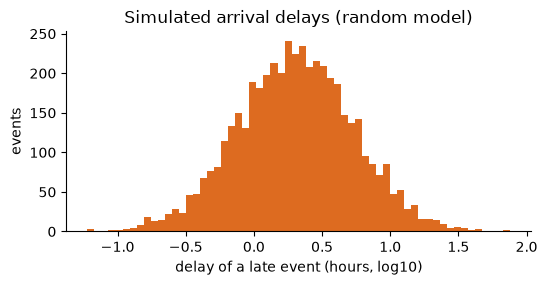

In [2]:
from lategraph.data import load_jodie
from lategraph.delays import make_delays, arrival_times

S = load_jodie("wikipedia")              # PyG JODIEDataset; downloads the csv the first time
print(S.summary())
delay = make_delays(S, "rand", seed=0)   # seconds of delay for every test event (0 = on time)
arrival = arrival_times(S, delay)        # a_e = t_e + delay
late = delay > 0
print(f"{late.mean():.1%} of the {len(delay):,} test events are late; median delay {np.median(delay[late]) / 3600:.1f} h")

fig, ax = plt.subplots(figsize=(6, 2.6))
ax.hist(np.log10(delay[late] / 3600), bins=60, color="#dd6b20")
ax.set_xlabel("delay of a late event (hours, log10)"); ax.set_ylabel("events")
ax.set_title("Simulated arrival delays (random model)")
plt.show()

## 3. TGN in PyG
The model is PyG's TGN exactly as in `examples/tgn.py`:

* **memory** — `torch_geometric.nn.TGNMemory` with `IdentityMessage` and `LastAggregator`: every node *n* updated in a
  batch takes its latest event *e* (with partner *o*) and updates
  $s_n \leftarrow \mathrm{GRU}([s_n \,\|\, s_o \,\|\, x_e \,\|\, \phi(t_e - \tau_n)],\; s_n)$;
* **embedding** — one `TransformerConv` over the node's last 10 temporal neighbours, with edge features
  $[\phi(\Delta t) \,\|\, x_e]$;
* **decoder** — an MLP link score $s(u, v)$.

We train for 3 epochs here (the models behind the blog post use 15 epochs and reach validation AP 0.965 on Wikipedia).

In [3]:
from lategraph.model import TGN, TGNConfig
from lategraph.train import train_tgn

t0 = time.time()
model, info = train_tgn(S, TGNConfig(), epochs=3, seed=0, threads=2)      # PyG TGN training loop (batch 200, Adam 1e-4)
print(f"validation AP {info['best_val_ap']:.4f} after {info['best_epoch']} epochs ({time.time() - t0:.0f} s)")
print(model.memory)                                                          # PyG's TGNMemory with a GRU update
print(model.gnn.conv)                                                        # PyG's TransformerConv

wikipedia seed 0 ep 01 loss 1.1122 val AP 0.8564 (8s)
wikipedia seed 0 ep 02 loss 0.8163 val AP 0.9212 (8s)
wikipedia seed 0 ep 03 loss 0.7167 val AP 0.9354 (8s)
validation AP 0.9354 after 3 epochs (25 s)
TGNMemory(
  (msg_s_module): IdentityMessage()
  (msg_d_module): IdentityMessage()
  (aggr_module): LastAggregator()
  (time_enc): TimeEncoder(
    (lin): Linear(in_features=1, out_features=100, bias=True)
  )
  (gru): GRUCell(472, 100)
)
TransformerConv(100, 50, heads=2)


## 4. Changing the past: `RetroactiveTGNMemory`
`RetroactiveTGNMemory` (in `lategraph/memory.py`) subclasses PyG's `TGNMemory`. During streaming it keeps a
**journal**: for every step, which node was updated with which event, and its memory before and after. To change the
past you call `edit(insert=..., delete=...)` (an amendment is a delete plus an insert), then `repair(mode)`:

* `"exact"` recomputes exactly the updates in the **dependency cone** — every later update that reads a memory the edit
  changed — and copies every other update from the journal. The result is the memory we would have had if the
  corrected stream had been processed in time order;
* `"replay"` rolls back and recomputes *everything* after the edit (same result, used as the reference);
* `"eps"` stops the change where it becomes tiny (relative change $\le \varepsilon$).

Below: we hold back one event of an early step, process 100 steps, then insert it late and repair. Exact repair and
replay give **the same memory, bit for bit**, but exact repair recomputes only the cone. (We pick the last event of its
step: with last-message aggregation, an event that is not the latest of its nodes in its step changes nothing at all.)

In [4]:
from lategraph.data import BatchGrid
from lategraph.memory import EventTable, RetroactiveTGNMemory

grid = BatchGrid(S.t, S.test0, 200, 100)                     # 100 test steps of 200 events (steps defined by time)
step = torch.full((S.num_events,), -1, dtype=torch.long)
test = torch.arange(S.test0, S.num_events)
step[test] = grid.step_of_time(S.t[test])
table = EventTable(S.src, S.dst, S.t, S.msg, step)           # every event the experiment may see, with its step

late_event = test[step[test] == 5][-1:]      # the last event of step 6 (the latest of both its nodes there) arrives late
base = RetroactiveTGNMemory.from_trained(model.memory, table)   # same weights as the trained TGNMemory
base.warmup(0, S.test0)                                      # process the history (train + validation) in order
for k in range(grid.J):
    ev = test[step[test] == k]
    base.advance(ev[~torch.isin(ev, late_event)])            # one journaled step

a = RetroactiveTGNMemory.from_trained(model.memory, table).copy_state_from(base)
b = RetroactiveTGNMemory.from_trained(model.memory, table).copy_state_from(base)
a.edit(insert=late_event); st_a = a.repair("exact")
b.edit(insert=late_event); st_b = b.repair("replay")
print("identical memories:", torch.equal(a.memory, b.memory),
      "| identical last-update times:", torch.equal(a.last_update, b.last_update))
print(f"exact repair recomputed {st_a.recomputed} node updates and visited "
      f"{st_a.extra['visited_steps']} of {st_a.steps} steps; replay recomputed {st_b.recomputed}")
print(f"memories changed by the late event: {st_a.changed_nodes} of {S.num_nodes:,} nodes")

identical memories: True | identical last-update times: True
exact repair recomputed 12 node updates and visited 6 of 95 steps; replay recomputed 14492
memories changed by the late event: 3 of 9,227 nodes


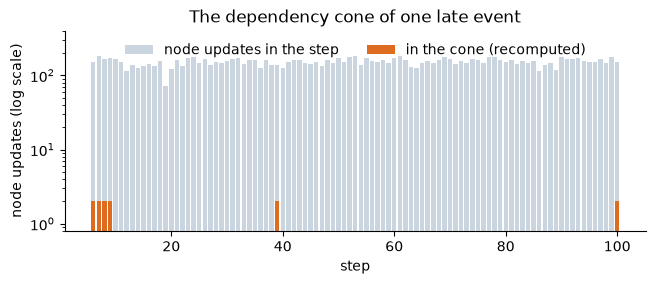

In [5]:
# Where is the cone? For every step after the edit, the nodes whose memory changed (orange) among all updated nodes.
changed_per_step, updated_per_step = [], []
for k in range(int(step[late_event]), grid.J):
    ra, rb = a.journal[k], base.journal[k]
    upd = ra.nodes.numel()
    diff = int(((ra.post_mem - rb.post_mem[torch.searchsorted(rb.nodes, ra.nodes).clamp(max=rb.nodes.numel() - 1)]).abs().amax(1) > 0).sum()) if upd else 0
    changed_per_step.append(diff); updated_per_step.append(upd)
fig, ax = plt.subplots(figsize=(7.5, 2.6))
ks = np.arange(int(step[late_event]), grid.J) + 1
ax.bar(ks, updated_per_step, color="#cbd5e0", label="node updates in the step")
ax.bar(ks, changed_per_step, color="#dd6b20", label="in the cone (recomputed)")
ax.set_yscale("log"); ax.set_ylim(0.8, 400)                  # log scale: the cone is a few updates out of ~150 per step
ax.set_xlabel("step"); ax.set_ylabel("node updates (log scale)"); ax.legend(frameon=False, ncol=2, loc="upper center")
ax.set_title("The dependency cone of one late event")
plt.show()

## 5. The step index: repair visits only the steps the cone touches
A naive repair rolls the memory back to the edited step and walks through every later step, even when nothing there
reads a changed memory. Our repair keeps, for every node, the steps where it is updated, and visits only steps that
contain an edit or a node whose memory changed. Everything an update reads is the memory of a node updated in the same
step, which the journal stores, so no global rollback is needed. The two versions are bit-identical
(`tests/test_index.py`); below we time both against full replay on 30 random edits.

{'indexed': '0.8 ms', 'walk': '8.2 ms', 'replay': '23.8 ms'} -> indexed exact repair is 29x faster than replay


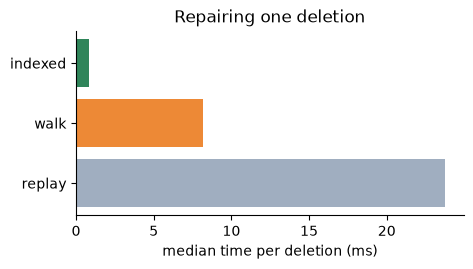

In [6]:
rng = np.random.default_rng(0)
win = test[step[test] < grid.J]
times = {"indexed": [], "walk": [], "replay": []}
w = RetroactiveTGNMemory.from_trained(model.memory, table)
for trial in range(30):
    dele = torch.tensor([int(rng.choice(win[win != late_event].numpy()))])     # a random deletion request
    for name in times:
        w.copy_state_from(base); w.use_index = name == "indexed"; w.edit(delete=dele)
        t0 = time.perf_counter(); w.repair("replay" if name == "replay" else "exact"); times[name].append(time.perf_counter() - t0)
med = {k: 1000 * np.median(v) for k, v in times.items()}
print({k: f"{v:.1f} ms" for k, v in med.items()}, f"-> indexed exact repair is {med['replay'] / med['indexed']:.0f}x faster than replay")
fig, ax = plt.subplots(figsize=(5, 2.4))
ax.barh(list(med)[::-1], list(med.values())[::-1], color=["#a0aec0", "#ed8936", "#2f855a"])
ax.set_xlabel("median time per deletion (ms)"); ax.set_title("Repairing one deletion")
plt.show()

## 6. Late events: wait, ignore, apply on arrival, or repair?
`lategraph.stream.evaluate_stream` runs several **policies** in lockstep on the same test steps. Before step *j* is
scored, each policy turns the events it has *received* (arrival time before the step) into a memory, then scores the
step's queries against 100 random and 100 historical negatives (MRR, ties count half). All policies share the weights,
the negatives and a neighbour store ordered by occurrence time, so they differ only in how they handle the memory:

* `oracle` sees every event on time (an upper bound no deployed system has);
* `exact` inserts late events into their own step and repairs the cone; `eps:0.05` stops tiny changes;
* `arrival` applies late events when they arrive; `drop` ignores them; `buffer:1` waits one hour before applying events.

In [7]:
from lategraph.stream import make_setup, sample_negatives, warm_start, Policy, evaluate_stream

setup = make_setup(S, arrival, bq=200, max_steps=60)          # the first 60 test steps (the paper uses all 119)
negs_r, negs_h = sample_negatives(S, setup, seed=1234)
mem0, store0 = warm_start(model, S, setup.table)
names = ["oracle", "exact", "eps:0.05", "arrival", "drop", "buffer:1"]
policies = [Policy(m, model, setup, mem0, store0) for m in names]
summary, arrays = evaluate_stream(model, setup, policies, negs_r, negs_h, ref="exact", log=None)
import pandas as pd
df = pd.DataFrame(summary["methods"]).T[["mrr", "cost_x_normal", "top1_agree", "sec"]]
df.columns = ["MRR", "compute (x normal)", "top-1 same as exact", "seconds"]
df.round(4)

,MRR,compute (x normal),top-1 same as exact,seconds
oracle,0.4589,1.0000,0.8571,0.0474
exact,0.4634,1.3131,1.0000,0.2610
eps:0.05,0.4635,1.2419,0.9958,0.2515
arrival,0.4633,1.1908,0.7659,0.0415
drop,0.4583,0.9001,0.7460,0.0360
buffer:1,0.4533,1.3126,0.5785,0.0651


## 7. Deleting from the log is not deleting from the memory
A user asks us to delete their interactions with an item. The weights were trained before the test period, so they
have never seen these events — but the **memory** has. We take user–item pairs that first meet in the test period:
half of them (A) are observed and then deleted at a request step, the other half (B) are never observed. After a
perfect deletion A and B look the same (membership AUC = 0.5). We compare deletion methods:

* `store`: delete the events from the log / neighbour list only (what a system does by default);
* `reset`: also zero the two endpoints' memories;
* `exact`: exact repair of the memory (the deleted events never happened).

and two attacks: the model's own link score, and a **likelihood-ratio attack** (LiRA, Carlini et al. 2022) that knows the
weights and simulates the stream with and without each pair (shadow runs) — the strongest attacker we can define.

In [8]:
from sklearn.metrics import roc_auc_score
from lategraph.neighbors import TimeOrderedNeighborStore
from lategraph.stream import score_pairs

jdel = grid.J // 2                                           # the deletion request arrives at step 50
pre_end = int((step >= 0).logical_and(step < jdel).nonzero().max()) + 1
src, dst = S.src.numpy(), S.dst.numpy()
hist_pairs = set(zip(src[:S.test0].tolist(), dst[:S.test0].tolist()))
pair_events = {}
for e in range(S.test0, pre_end):
    pair_events.setdefault((int(src[e]), int(dst[e])), []).append(e)
ucnt = np.bincount(src[:pre_end], minlength=S.num_nodes)
cands = [p for p, ev in pair_events.items() if p not in hist_pairs and ucnt[p[0]] - len(ev) >= 3]   # new pairs, active users
perm = np.random.default_rng(0).permutation(len(cands))
A = [cands[i] for i in perm[0::2]]; B = [cands[i] for i in perm[1::2]]
P = A + B; y = np.r_[np.ones(len(A)), np.zeros(len(B))]
pev = [torch.tensor(pair_events[p]) for p in P]
u = torch.tensor([p[0] for p in P]); v = torch.tensor([p[1] for p in P])
steps_ev = [test[step[test] == j] for j in range(jdel)]
warm = RetroactiveTGNMemory.from_trained(model.memory, table); warm.warmup(0, S.test0)
hist_store = TimeOrderedNeighborStore(S.src, S.dst, S.t, S.num_nodes, 10); hist_store.rebuild_from(torch.arange(S.num_events) < S.test0)
print(f"{len(A)} pairs observed and deleted (A), {len(B)} never observed (B)")

def state(observed):
    # memory and neighbour store at the request step when only the pairs `observed` were observed
    hidden = torch.zeros(S.num_events, dtype=torch.bool)
    for i in np.flatnonzero(~observed): hidden[pev[i]] = True
    mem = RetroactiveTGNMemory.from_trained(model.memory, table).copy_state_from(warm)
    for j in range(jdel): mem.advance(steps_ev[j][~hidden[steps_ev[j]]])
    store = hist_store.clone(); ins = torch.arange(S.test0, pre_end); store.insert(ins[~hidden[ins]])
    D = torch.cat([pev[i] for i in np.flatnonzero(observed)]).sort().values
    return mem, store, D

def delete_with(method, mem0, store0, D):
    # apply a deletion method to a copy of the state
    mem = RetroactiveTGNMemory.from_trained(model.memory, table).copy_state_from(mem0)
    store = store0.clone(); store.remove(D)                  # every method removes the events from the log
    if method == "reset":
        ep = torch.cat([S.src[D], S.dst[D]]).unique(); mem.memory[ep] = 0; mem.last_update[ep] = 0
    elif method == "exact":
        mem.edit(delete=D); mem.repair("exact")
    return mem, store

def link_scores(mem, store):
    return score_pairs(model, mem, store, table, u, v, int(grid.T[jdel])).numpy()

methods = ["store", "reset", "exact"]
m0, s0, D0 = state(np.r_[np.ones(len(A), bool), np.zeros(len(B), bool)])
target = {m: link_scores(*delete_with(m, m0, s0, D0)) for m in methods}

285 pairs observed and deleted (A), 284 never observed (B)


In [9]:
# LiRA with counterfactual shadow streams: random halves of the candidate pairs are observed and deleted with the same
# method; per pair this gives score distributions IN and OUT (Gaussians, pooled variance); the statistic is their log ratio.
R = 8                                                        # shadow streams (the paper uses 64)
IN = np.random.default_rng(1).random((R, len(P))) < 0.5
SC = {m: np.zeros((R, len(P))) for m in methods}
for r in range(R):
    mr, sr, Dr = state(IN[r])
    for m in methods: SC[m][r] = link_scores(*delete_with(m, mr, sr, Dr))

rows = {}
for m in methods:
    sc, s = SC[m], target[m]
    mu_in = np.where(IN, sc, 0).sum(0) / np.maximum(IN.sum(0), 1); mu_out = np.where(~IN, sc, 0).sum(0) / np.maximum((~IN).sum(0), 1)
    floor = 1e-12 + 1e-6 * sc.var()
    var_in = max(np.where(IN, (sc - mu_in) ** 2, 0).sum() / max(IN.sum() - len(P), 1), floor)
    var_out = max(np.where(~IN, (sc - mu_out) ** 2, 0).sum() / max((~IN).sum() - len(P), 1), floor)
    lam = -(s - mu_in) ** 2 / (2 * var_in) + (s - mu_out) ** 2 / (2 * var_out) - 0.5 * np.log(var_in / var_out)
    ok = (IN.sum(0) > 0) & ((~IN).sum(0) > 0)
    rows[m] = dict(link_score_AUC=roc_auc_score(y, s), LiRA_AUC=roc_auc_score(y[ok], lam[ok]))
pd.DataFrame(rows).T.round(3)

,link_score_AUC,LiRA_AUC
store,0.591,0.791
reset,0.623,0.817
exact,0.527,0.507


## 8. A memory that provably forgets small errors
ε-repair is cheaper than exact repair, but it leaves small errors. Do they fade or snowball? If every update shrinks
memory differences by a factor $\rho < 1$, an error that is skipped once can never grow beyond $r/(1-\rho)$. A trained
TGN's GRU does not do this (its median Jacobian norm is above 1). Our `ContractiveRNNCell` does, **for every input**:

$$s' = (1 - a)\odot s + a \odot \tanh(W[s \,\|\, p \,\|\, x \,\|\, \phi] + b), \qquad
\|W_{i,\text{memory}}\|_1 \le c, \quad a_i \ge a_{\min}$$

gives $\|s'(s,p) - s'(\tilde s,\tilde p)\|_\infty \le \rho \max(\|s-\tilde s\|_\infty, \|p-\tilde p\|_\infty)$ with
$\rho = 1 - a_{\min}(1-c)$. It drops into PyG's `TGNMemory` as `memory.gru`. We check the inequality on random inputs,
train a contractive TGN for 3 epochs, and check the proven bound during ε-repair.

In [10]:
from lategraph.model import ContractiveRNNCell
cell = ContractiveRNNCell(2 * 16 + 8, 16, a_min=0.2, c=0.5)
for p_ in cell.parameters(): torch.nn.init.normal_(p_, std=2.0)        # big weights: the constraint does the work
s1, p1, x = torch.randn(512, 16) * 3, torch.randn(512, 16) * 3, torch.randn(512, 8)
s2, p2 = s1 + torch.randn(512, 16), p1 + torch.randn(512, 16)
ratio = (cell(torch.cat([s1, p1, x], 1), s1) - cell(torch.cat([s2, p2, x], 1), s2)).abs().amax(1) / \
        torch.maximum((s1 - s2).abs().amax(1), (p1 - p2).abs().amax(1))
print(f"rho of the cell = {cell.rho():.3f} (guaranteed <= {1 - 0.2 * 0.5:.2f}); largest measured ratio {ratio.max():.3f}")

cmodel, cinfo = train_tgn(S, TGNConfig(updater="crnn", crnn_amin=0.2, crnn_c=0.5), epochs=3, seed=0, threads=2)
print(f"contractive TGN: validation AP {cinfo['best_val_ap']:.4f}; its proven rho = {cmodel.memory.gru.rho():.3f}")

rho of the cell = 0.895 (guaranteed <= 0.90); largest measured ratio 0.796
wikipedia seed 0 ep 01 loss 1.2450 val AP 0.8466 (8s)
wikipedia seed 0 ep 02 loss 0.9124 val AP 0.8972 (8s)
wikipedia seed 0 ep 03 loss 0.8192 val AP 0.9071 (8s)
contractive TGN: validation AP 0.9071; its proven rho = 0.704


In [11]:
# eps-repair on the contractive TGN: the error of every node stays below b_n <- rho * max(b_n, b_partner) + skipped change
rho = cmodel.memory.gru.rho()
cbase = RetroactiveTGNMemory.from_trained(cmodel.memory, table); cbase.warmup(0, S.test0)
for k in range(grid.J): cbase.advance(test[step[test] == k])
cw = RetroactiveTGNMemory.from_trained(cmodel.memory, table)
holds, ratios = [], []
for trial in range(20):
    dele = torch.from_numpy(rng.choice(win.numpy(), 3, replace=False))
    cw.copy_state_from(cbase); cw.edit(delete=dele); cw.repair("exact"); exact_mem = cw.memory.clone()
    bound = torch.zeros(S.num_nodes)
    def hook(k, nodes, other, eid, skipped, skip_diff, mem_, lu_):          # called once per step of the repair walk
        bound[nodes] = rho * torch.maximum(bound[nodes], bound[other]) + skip_diff
    cw.copy_state_from(cbase); cw.edit(delete=dele); st = cw.repair("eps", eps=0.2, hook=hook)
    err = (cw.memory - exact_mem).abs().amax(1)
    holds.append(bool((err <= bound + 1e-6).all()))
    if err.max() > 0: ratios.append(float(bound.max() / err.max()))
print(f"proven bound held in {np.mean(holds):.0%} of {len(holds)} trials; median bound / true worst error = {np.median(ratios):.1f}")

proven bound held in 100% of 20 trials; median bound / true worst error = 9.3


## 9. Exact counterfactual explanations
With exact repair we can answer *what if this event had never happened?* exactly and cheaply. For a few test
predictions $s(u, v)$ we delete each of the user's last 20 events in turn and measure how much the score moves —
through the **memory** (repair it) and through the **neighbour list** that `TransformerConv` attends over. Attention
weights are a popular explanation; are they right? Attention only ever sees the last 10 events, while memory carries
the influence of older ones.

In [12]:
from scipy.stats import spearmanr
j0 = grid.J - 1                                              # explain the predictions of the last step
base_j0 = RetroactiveTGNMemory.from_trained(model.memory, table).copy_state_from(warm)
for k in range(j0): base_j0.advance(test[step[test] == k])   # memory before step j0, with the journal
store_j0 = TimeOrderedNeighborStore(S.src, S.dst, S.t, S.num_nodes, 10)
seen = torch.arange(S.num_events) < S.test0; seen[test[step[test] < j0]] = True; store_j0.rebuild_from(seen)
user_ev = {}
for e in test[(step[test] < j0)].tolist(): user_ev.setdefault(int(S.src[e]), []).append(e)
queries = [e for e in test[step[test] == j0].tolist() if len(user_ev.get(int(S.src[e]), [])) >= 20][:15]
rho_att, outside, top1 = [], [], []
work = RetroactiveTGNMemory.from_trained(model.memory, table)
for eq in queries:
    uq, vq = int(S.src[eq]), int(S.dst[eq]); now = int(grid.T[j0])
    n_id = torch.tensor(sorted({uq, vq})); all_id, ei, e_id = store_j0(n_id)
    loc = {int(x): i for i, x in enumerate(all_id)}
    z, (ei2, alpha) = model.gnn(base_j0.memory[all_id], base_j0.last_update[all_id], ei, table.t[e_id], table.msg[e_id], return_attention=True)
    s0q = float(model.score(z[[loc[uq]]], z[[loc[vq]]]))
    att = {int(e_id[i]): float(alpha[i].mean()) for i in (ei[1] == loc[uq]).nonzero().view(-1).tolist()}
    infl = {}
    for e in user_ev[uq][-20:]:
        work.copy_state_from(base_j0); work.edit(delete=torch.tensor([e])); work.repair("exact")
        st_ = store_j0.clone(); st_.remove(torch.tensor([e]))
        infl[e] = abs(s0q - float(score_pairs(model, work, st_, table, torch.tensor([uq]), torch.tensor([vq]), now)))
    tot = sum(infl.values()) + 1e-12
    outside.append(sum(v_ for e, v_ in infl.items() if e not in att) / tot)
    common = [e for e in att if e in infl]
    if len(common) >= 3:
        rho_att.append(spearmanr([att[e] for e in common], [infl[e] for e in common]).statistic)
        top1.append(max(common, key=lambda e: att[e]) == max(infl, key=infl.get))
print(f"{len(queries)} predictions: {np.mean(outside):.0%} of the influence comes from events attention never sees; "
      f"Spearman(attention, influence) = {np.nanmedian(rho_att):+.2f}; the most-attended event is the most influential one in {np.mean(top1):.0%}")

15 predictions: 17% of the influence comes from events attention never sees; Spearman(attention, influence) = +0.47; the most-attended event is the most influential one in 7%


## 10. All results of the blog post (and of our paper draft)
Every experiment wrote a small JSON file (`results/`, one per run; 5 seeds for the main settings), and
`scripts/aggregate.py` collected them into `results/summary.json`. This section reads that file and draws the main
results. (Re-running everything takes about a day on a laptop CPU: see the README's job lists.)

In [13]:
SUMMARY = os.path.join(CODE_DIR, "results", "summary.json")
R = json.load(open(SUMMARY))
print({k: len(v) for k, v in R.items()})

{'training': 29, 'streaming': 41, 'exactness': 9, 'deletion': 15, 'contraction': 17, 'lira': 11, 'lira_know': 37, 'train_deletion': 6, 'influence': 3, 'dyrep': 3}


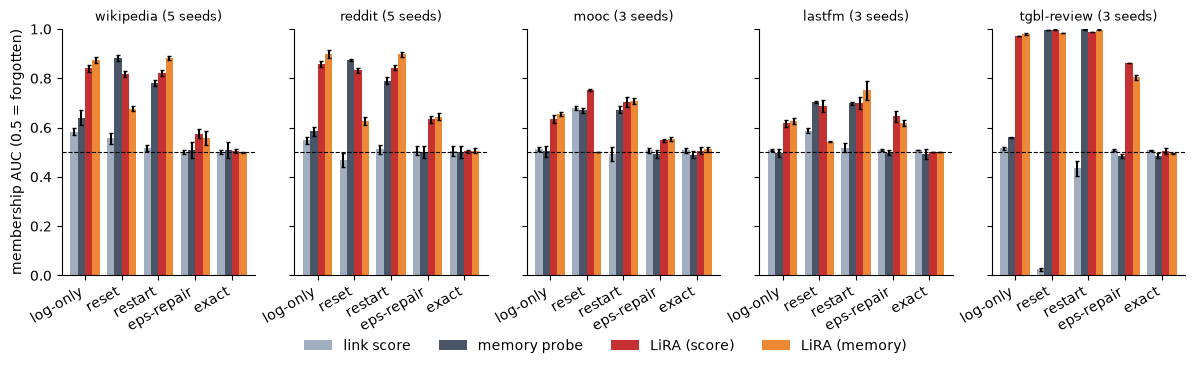

In [14]:
# 10a. The deletion leak (all attacks; blog Figure 5 shows the strongest): membership AUC of each deletion method under four attacks, mean +- std over seeds
def agg(entry):                     # an aggregated result is {"mean", "std", "n", "values"}
    return (entry["mean"], entry["std"]) if entry else (np.nan, 0)

methods = [("store", "log-only"), ("reset", "reset"), ("restart", "restart"), ("eps:0.05", "eps-repair"), ("exact", "exact")]
datasets = [d for d in ["wikipedia", "reddit", "mooc", "lastfm", "tgbl-review"] if f"{d}|attn" in R["lira"]]
fig, axes = plt.subplots(1, len(datasets), figsize=(2.9 * len(datasets), 3.2), sharey=True)
for ax, ds in zip(axes, datasets):
    L = R["lira"][f"{ds}|attn"]["methods"]
    P = R["deletion"].get(f"main|{ds}|attn", {}).get("methods", {})
    attacks = [("link score", lambda m: L.get(m, {}).get("raw_logit_auc"), "#a0aec0"),
               ("memory probe", lambda m: P.get(m, {}).get("attacks", {}).get("probe_0"), "#4a5568"),
               ("LiRA (score)", lambda m: L.get(m, {}).get("logit_auc"), "#c53030"),
               ("LiRA (memory)", lambda m: L.get(m, {}).get("cosine_auc"), "#ed8936")]
    for j, (lab, getter, col) in enumerate(attacks):
        vals = [agg(getter(m)) for m, _ in methods]
        ax.bar(np.arange(len(methods)) + (j - 1.5) * 0.2, [v[0] for v in vals], 0.2, yerr=[v[1] for v in vals], color=col, label=lab, capsize=1.5)
    n_seeds = R["lira"][f"{ds}|attn"]["n"]
    ax.axhline(0.5, color="k", ls="--", lw=0.8); ax.set_ylim(0.0, 1.0); ax.set_title(f"{ds} ({n_seeds} seed{'s' * (n_seeds > 1)})", fontsize=9)
    ax.set_xticks(range(len(methods))); ax.set_xticklabels([l for _, l in methods], rotation=30, ha="right")
axes[0].set_ylabel("membership AUC (0.5 = forgotten)")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncol=4, bbox_to_anchor=(0.5, -0.05), frameon=False)
plt.show()

In [15]:
# 10a'. The leak against weaker attackers: LiRA on the link score after log-only deletion and after resetting the memories,
# when the attacker knows only part of the other events, attacks some steps after the request, or fewer pairs are unknown (K)
variants = [("", "full knowledge"), ("know0.5", "knows 50% of the other events"), ("know0.1", "knows 10%"), ("know0", "knows none"),
            ("after20", "20 steps after the request"), ("after50", "50 steps after"), ("K100", "K = 100 pairs"), ("K25", "K = 25 pairs")]
tab = {}
for tag, lab in variants:
    row = {}
    for ds in ["wikipedia", "reddit", "mooc", "lastfm", "tgbl-review"]:
        M = (R["lira"].get(f"{ds}|attn") if not tag else R["lira_know"].get(f"{ds}|attn|{tag}") or {}).get("methods", {})
        for m, ml in [("store", "log-only"), ("reset", "reset")]:
            row[(ds, ml)] = M.get(m, {}).get("logit_auc", {}).get("mean", np.nan)
    tab[lab] = row
pd.DataFrame(tab).T.round(2)

wikipedia        ... tgbl-review      
                               log-only reset  ...    log-only reset
full knowledge                     0.84  0.82  ...        0.97  1.00
knows 50% of the other events      0.70  0.74  ...        0.57  0.97
knows 10%                          0.65  0.67  ...        0.53  0.97
knows none                         0.63  0.63  ...        0.52  0.97
20 steps after the request         0.84  0.81  ...        0.97  1.00
50 steps after                     0.83  0.82  ...        0.97  1.00
K = 100 pairs                      0.92  0.89  ...         NaN   NaN
K = 25 pairs                       0.97  0.95  ...         NaN   NaN

[8 rows x 10 columns]

In [16]:
# 10b. Late events (blog Figure 7, paper Table 4): MRR change of each policy relative to exact repair (%), and its compute
rows = {}
for ds in ["wikipedia", "reddit", "mooc", "lastfm"]:
    G = R["streaming"].get(f"main|{ds}|attn|rand|bq200")
    if not G: continue
    M = G["methods"]
    rows[ds] = {f"{m} (MRR %)": M[m]["dmrr_rel_pct"]["mean"] for m in ["oracle", "arrival", "drop", "buffer:1", "eps:0.05"] if m in M}
    rows[ds].update({f"{m} (compute x)": M[m]["cost_x_normal"]["mean"] for m in ["replay", "exact", "eps:0.05"] if m in M})
pd.DataFrame(rows).round(2)

,wikipedia,reddit,mooc,lastfm
oracle (MRR %),0.45,0.13,0.43,-0.23
arrival (MRR %),0.13,-0.13,0.13,2.32
drop (MRR %),0.04,-0.06,0.40,1.77
buffer:1 (MRR %),-4.92,-1.53,-11.33,-4.74
eps:0.05 (MRR %),0.01,-0.01,0.32,0.09
replay (compute x),16.72,69.37,48.97,5.88
exact (compute x),1.30,13.69,23.10,1.11
eps:0.05 (compute x),1.24,1.89,2.20,1.08


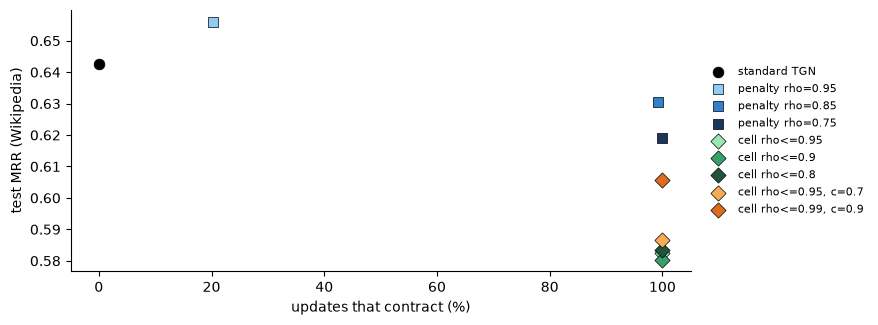

In [17]:
# 10c. Repairability against accuracy (blog Figure 6): certified share of updates vs test MRR, standard / penalty / contractive cell
fig, ax = plt.subplots(figsize=(8, 3.4))
for var, lab, col, mk in [("attn", "standard TGN", "k", "o"), ("rho0.95_lam10", "penalty rho=0.95", "#90cdf4", "s"),
                          ("rho0.85_lam10", "penalty rho=0.85", "#3182ce", "s"), ("rho0.75_lam10", "penalty rho=0.75", "#1a365d", "s"),
                          ("crnn0.95", "cell rho<=0.95", "#9ae6b4", "D"), ("crnn0.9", "cell rho<=0.9", "#38a169", "D"),
                          ("crnn0.8", "cell rho<=0.8", "#22543d", "D"), ("crnn0.95c0.7", "cell rho<=0.95, c=0.7", "#f6ad55", "D"),
                          ("crnn0.99c0.9", "cell rho<=0.99, c=0.9", "#dd6b20", "D")]:
    c, st = R["contraction"].get(f"wikipedia|{var}"), R["streaming"].get(f"main|wikipedia|{var}|rand|bq200")
    if not c or not st: continue
    cert = 100.0 if var.startswith("crnn") else 100 * c["certified"]["mean"]      # the cell contracts by construction
    ax.scatter(cert, st["methods"]["oracle"]["mrr"]["mean"], color=col, marker=mk, s=60, edgecolor="k", lw=0.5, label=lab)
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False, fontsize=8)
ax.set_xlabel("updates that contract (%)"); ax.set_ylabel("test MRR (Wikipedia)")
plt.show()

In [18]:
# 10d. Exact counterfactual explanations (blog Figure 8): how much of a prediction's influence attention cannot see
shares = ["share_outside_list", "share_memory_channel", "top1_attention_is_top1_influence", "top1_influence_inside_list"]
tab = {ds: {k: f"{100 * I[k]['mean']:.0f}% +- {100 * I[k]['std']:.0f}" for k in shares} for ds, I in R["influence"].items()}
for ds, I in R["influence"].items():
    tab[ds]["Spearman(attention, influence)"] = f"{I['spearman_att_vs_influence_median']['mean']:+.2f} +- {I['spearman_att_vs_influence_median']['std']:.2f}"
    tab[ds]["predictions explained per model"] = f"{I['queries']['mean']:.0f}"
pd.DataFrame(tab)

,mooc,reddit,wikipedia
share_outside_list,8% +- 4,11% +- 1,9% +- 2
share_memory_channel,59% +- 4,45% +- 2,48% +- 2
top1_attention_is_top1_influence,10% +- 7,18% +- 5,16% +- 11
top1_influence_inside_list,99% +- 1,99% +- 1,95% +- 5
"Spearman(attention, influence)",-0.03 +- 0.12,+0.10 +- 0.04,+0.10 +- 0.07
predictions explained per model,100,62,93


In [19]:
# 10e. Exactness (blog Table 1): random edits, largest difference to a fresh recomputation, share of bit-identical trials, cone size
E = R["exactness"]
pd.DataFrame({k.replace("exactness_", ""): {"trials": v["summary"]["trials"], "max |diff|": f"{v['summary']['max_abs_diff']:.1e}",
                                            "bit-identical": f"{100 * v['summary']['frac_exact_zero']:.0f}%",
                                            "median cone": f"{100 * v['cone_frac_median']:.2f}%" if "cone_frac_median" in v else "-"}
              for k, v in E.items()}).T

,trials,max |diff|,bit-identical,median cone
tgn_lastfm_s0,1977,0.0e+00,100%,5.78%
tgn_mooc_s0,2960,1.0e-06,70%,0.05%
tgn_reddit_s0,2960,9.1e-07,72%,0.38%
tgn_tgbl-review_s0,982,6.0e-08,86%,0.02%
tgn_wikipedia_s0,3945,5.4e-07,98%,0.02%
tgn_wikipedia_s0_crnn0.9,1977,3.0e-08,99%,0.03%
tgn_wikipedia_s0_f64,983,0.0e+00,100%,0.03%
tgn_wikipedia_s0_jodie,1977,2.5e-06,49%,0.03%
tgn_wikipedia_s0_nopad,983,5.0e-02,74%,0.03%


In [20]:
# 10f. Memory models on Wikipedia (blog Table 2): validation AP, test MRR (oracle policy), leak after log-only deletion
rows = {}
for var, lab in [("attn", "TGN"), ("id", "memory-only TGN"), ("jodie", "JODIE"), ("crnn0.9", "TGN + contractive cell"), ("nomem", "memory-free")]:
    tr, st, li = R["training"].get(f"wikipedia|{var}"), R["streaming"].get(f"main|wikipedia|{var}|rand|bq200"), R["lira"].get(f"wikipedia|{var}")
    leak = li["methods"]["store"]["logit_auc"]["mean"] if li else np.nan      # LiRA on the link score (query access)
    rows[lab] = {"val AP": tr["val_ap"]["mean"] if tr else np.nan, "test MRR": st["methods"]["oracle"]["mrr"]["mean"] if st else np.nan,
                 "LiRA on scores after log-only deletion": leak}
dy = R["dyrep"]["wikipedia"]
rows["DyRep"] = {"val AP": dy["val_ap"]["mean"], "test MRR": dy["mrr"]["mean"],
                 "LiRA on scores after log-only deletion": dy["deletion"]["store"]["lira_logit"]["mean"]}
pd.DataFrame(rows).T.round(3)

,val AP,test MRR,LiRA on scores after log-only deletion
TGN,0.965,0.643,0.841
memory-only TGN,0.950,0.532,0.892
JODIE,0.957,0.536,0.880
TGN + contractive cell,0.939,0.580,0.798
memory-free,0.843,0.414,NaN
DyRep,0.945,0.528,0.749


In [21]:
# 10g. Deleting training-period pairs: link-score AUC after each method (rows: dataset; "recent" = last 20% of training)
tab = {ds: dict(seeds=T["n"], **{m: f"{v['logit']['mean']:.3f} +- {v['logit']['std']:.3f}" for m, v in T["methods"].items()})
       for ds, T in R["train_deletion"].items()}
pd.DataFrame(tab).T

,seeds,none,store,memory,finetune,retrain
mooc,3,0.494 +- 0.031,0.492 +- 0.032,0.489 +- 0.032,0.489 +- 0.034,0.489 +- 0.024
mooc|recent,1,0.527 +- 0.000,0.525 +- 0.000,0.522 +- 0.000,0.480 +- 0.000,0.531 +- 0.000
reddit,3,0.516 +- 0.008,0.508 +- 0.008,0.500 +- 0.009,0.486 +- 0.009,0.500 +- 0.023
reddit|recent,1,0.528 +- 0.000,0.511 +- 0.000,0.499 +- 0.000,0.484 +- 0.000,0.510 +- 0.000
wikipedia,5,0.553 +- 0.021,0.520 +- 0.021,0.501 +- 0.018,0.490 +- 0.003,0.517 +- 0.022
wikipedia|recent,3,0.584 +- 0.016,0.535 +- 0.015,0.502 +- 0.014,0.512 +- 0.023,0.492 +- 0.023


## Summary
* Deleting from the log is not deleting from a temporal GNN's memory: a likelihood-ratio attack on the model's scores finds
  the deleted pairs, also when it knows only part of the other events or attacks long after the request; resets and learned
  restarts leave a fingerprint. Exact repair of the dependency cone is at chance by construction.
* Exact repair is exact (bit for bit in float64, journal included) once kernels are batch-invariant; the step index makes it
  an order of magnitude faster than replay for recent edits, while old edits on hub-heavy graphs are better replayed.
* A memory update that is a contraction by construction turns the error bound of cheap repair into a guarantee.
* Exact counterfactuals show that attention weights are not explanations of a memory-based model.

**References.** Rossi et al. (TGN, 2020); Kumar et al. (JODIE, KDD 2019); Trivedi et al. (DyRep, ICLR 2019); Carlini et al.
(LiRA, S&P 2022); Huang et al. (TGB, NeurIPS 2023); Zhang et al. (TIGER, WWW 2023); Fey & Lenssen (PyG, 2019).